# Predicción del nivel del río con machine learning

## Contexto
Este notebook es un ejercicio de aprendizaje de machine learning.
Trabajamos con el nivel instantáneo del río Magdalena (medición horaria) para practicar preparación de datasets, evaluación de modelos de aprendizaje supervisado y diseño de experimentos.

El río Magdalena tiene una extensión de 1.540 kilómetros y atraviesa hasta 13 departamentos del territorio colombiano. Su nivel
se mide con sensores. *Este dataset fue extraído desde la página oficial de Datos Abiertos Colombia y se puede obtener en el siguiente enlace: [Dataset utilizado](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-Instant-neo-del-Rio/bdmn-sqnh/explore/query/SELECT%20%60fechaobservacion%60%2C%20%60valorobservado%60%0AWHERE%20caseless_one_of%28%60codigoestacion%60%2C%20"0025027020"%29/page/filter).*

## Los datos
Tenemos una **serie de tiempo**: un sensor registró el nivel del agua en
distintos horarios. Los datos están en `dataset_crudo.csv`
y cubren desde el 1 de enero de 2005 hasta el 15 de octubre de 2026, de la estación EL BANCO - AUT (código 25027020).

## Objetivo del experimento
Queremos usar machine learning para predecir o pronosticar cuál será el nivel del río Magdalena en mes especifico del año.

## Pasos del notebook
1. Cargar y revisar los datos
2. Limpiar los datos (valores vacíos o raros)
3. [Preparar los datos para el modelo]
4. [Entrenar y probar los modelos]
5. [Comparar resultados y conclusiones]

# Paso 1: Cargar y revisar los datos.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [31]:

df = pd.read_csv("dataset_crudo.csv")

df.info()
print(f"Filas: {df.shape[0]}  Columnas: {df.shape[1]}")
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 315757 entries, 0 to 315756
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  315757 non-null  str  
 1   ValorObservado    315757 non-null  str  
dtypes: str(2)
memory usage: 4.8 MB
Filas: 315757  Columnas: 2


,FechaObservacion,ValorObservado
0,2011 Aug 15 11:00:00 AM,"6,73"
1,2005 Nov 15 02:00:00 PM,"6,15"
2,2011 May 10 05:00:00 AM,"9,43"
3,2009 Apr 29 07:00:00 AM,"7,25"
4,2016 Sep 17 07:00:00 PM,"6,12"


## Organizacion y transformación de los datos.

Convertiremos los datos en en tipos de datos que podamos usar para los proximos calculos que haremos posteriormente.

In [32]:
df["ValorObservado"] = df["ValorObservado"].str.replace(",", ".")
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

print(f"Datos valor observado con errores al convertir: {df["ValorObservado"].isna().sum()}")

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], errors="coerce")

print(f"Datos fecha observada con errores al convertir: {df["FechaObservacion"].isna().sum()}")

df.info()

Datos valor observado con errores al convertir: 0
Datos fecha observada con errores al convertir: 0
<class 'pandas.DataFrame'>
RangeIndex: 315757 entries, 0 to 315756
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  315757 non-null  datetime64[us]
 1   ValorObservado    315757 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 4.8 MB


Con esto podemos verificar que efectivamente los datos esta en un tipo de dato con el cual podemos trabajar y no existe algún dato corrupto o faltante.

In [33]:
df_filtrado = df.sort_values("FechaObservacion").reset_index(drop=True)

filas_identicas = df_filtrado.duplicated().sum()

fechas_repetidas = df_filtrado.duplicated(subset=["FechaObservacion"]).sum()

conteo = df_filtrado["FechaObservacion"].value_counts()
conteo = conteo[conteo > 1]

print("Filas idénticas:", filas_identicas)
print("Filas con fecha repetida (sin la primera):", fechas_repetidas)
print("Fechas distintas que se repiten:", len(conteo))

df_filtrado[df_filtrado.duplicated(subset=["FechaObservacion"], keep=False)]


Filas idénticas: 18054
Filas con fecha repetida (sin la primera): 18054
Fechas distintas que se repiten: 17469


,FechaObservacion,ValorObservado
102490,2019-08-28 00:00:00,6.39
102491,2019-08-28 00:00:00,6.39
102492,2019-08-28 00:00:00,6.39
102493,2019-08-28 01:00:00,6.39
102494,2019-08-28 01:00:00,6.39
...,...,...
314318,2026-07-24 23:00:00,4.91
314319,2026-07-24 23:00:00,4.91
314320,2026-07-24 23:00:00,4.91
314321,2026-07-24 23:00:00,4.91


Hay 18.054 filas que son copias exactas de otra fila (misma fecha y mismo valor), y están repartidas en 17.469 fechas distintas

No se encontró ninguna fecha con valores diferentes.

Si se eliminaran las copias, quedarían 315.757 − 18.054 = 297.703 filas.

In [34]:
df_unico = df_filtrado.drop_duplicates().reset_index(drop=True)

print("Antes:", df_filtrado.shape[0])
print("Después:", df_unico.shape[0])
print("Eliminadas:", df_filtrado.shape[0] - df_unico.shape[0])
print("Fechas que aún se repiten:", df_unico.duplicated(subset=["FechaObservacion"]).sum())

Antes: 315757
Después: 297703
Eliminadas: 18054
Fechas que aún se repiten: 0


Con nuestro dataset libre de datos erroneos y/o repetidos continuamos analizando la frecuencia en la que son tomados los datos.

In [35]:
diferencias = df_unico["FechaObservacion"].diff()
print("Frecuencia en que se toma\n", diferencias.value_counts().head(10))
print("Intervalo más pequeño:", diferencias.min())
print("Intervalo más grande:", diferencias.max())


Frecuencia en que se toma
 FechaObservacion
0 days 00:10:00    181728
0 days 01:00:00    114485
0 days 00:40:00       527
0 days 00:20:00       193
0 days 02:00:00       111
0 days 01:10:00        81
0 days 00:30:00        44
0 days 05:00:00        35
0 days 01:40:00        21
0 days 04:00:00        17
Name: count, dtype: int64
Intervalo más pequeño: 0 days 00:01:00
Intervalo más grande: 931 days 01:00:00


Observamos que entre nuestros datos hubo un periodo en donde la toma del registro sucedía cada 10 minutos y otro periodo donde se tomaba cada 1 hora.
Se puede observar también que tenemos intervalos de varios días lo que nos indica que hubo periodos en donde no se tomó datos.

In [36]:
print(diferencias[diferencias > pd.Timedelta(days=1)].sort_values(ascending=False).head(10))
resumen = df_unico.assign(dif=diferencias, anio=df_unico["FechaObservacion"].dt.year)
resumen.groupby("anio")["dif"].median()


64129    931 days 01:00:00
113365   570 days 09:20:00
62269     29 days 10:00:00
79689     29 days 02:00:00
226995    21 days 00:10:00
296269    18 days 01:00:00
81654     13 days 19:00:00
113291     7 days 17:00:00
121335     7 days 00:10:00
122215     6 days 16:00:00
Name: FechaObservacion, dtype: timedelta64[us]


anio
2005   0 days 01:00:00
2006   0 days 01:00:00
2007   0 days 01:00:00
2008   0 days 01:00:00
2009   0 days 01:00:00
2010   0 days 01:00:00
2011   0 days 01:00:00
2012   0 days 01:00:00
2015   0 days 01:00:00
2016   0 days 01:00:00
2017   0 days 01:00:00
2018   0 days 01:00:00
2019   0 days 01:00:00
2020   0 days 01:00:00
2021   0 days 01:00:00
2022   0 days 00:10:00
2023   0 days 00:10:00
2024   0 days 00:10:00
2025   0 days 00:10:00
2026   0 days 00:10:00
Name: dif, dtype: timedelta64[us]

Según los intervalos entre registros, entre 2005 y 2021 las mediciones se tomaban cada hora, y a partir de 2022 hasta 2026 se toman cada 10 minutos.

Además, se observa un periodo de aproximadamente dos años y medio sin registros, que abarca los años 2013 y 2014 completos. Esto concuerda con el intervalo de 931 días que encontramos anteriormente.

In [37]:
serie = df_unico.set_index("FechaObservacion")["ValorObservado"]
diario = serie.resample("D").mean()
semanal = serie.resample("W").mean()

print("Dias promediados contando dias sin registro", len(diario))
print("Dias promediados que tienen registro", diario.count(), "\n")

print("Semanas promediadas contando semanas sin registro", len(semanal))
print("Semanas promediados que tienen registro", semanal.count())

Dias promediados contando dias sin registro 7957
Dias promediados que tienen registro 6254 

Semanas promediadas contando semanas sin registro 1138
Semanas promediados que tienen registro 914


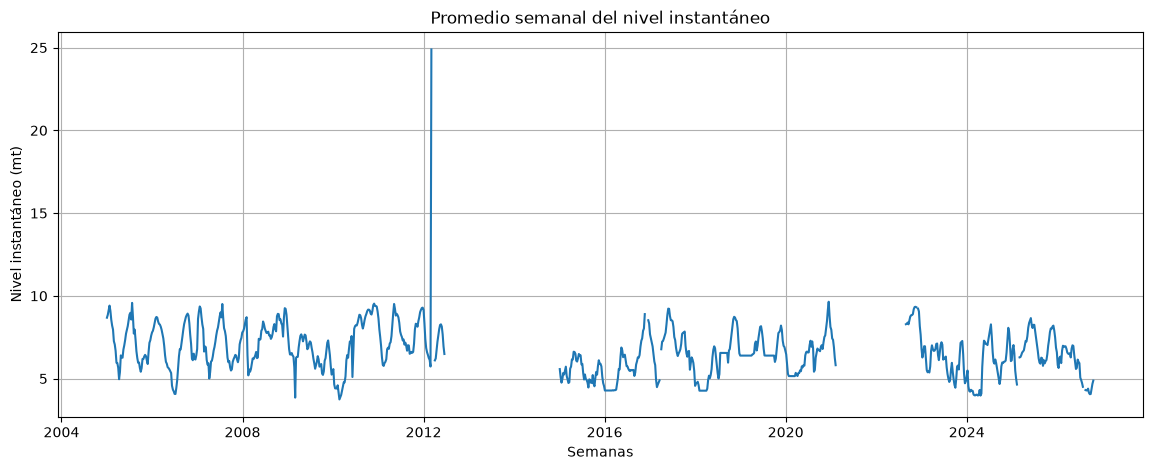

In [38]:
plt.figure(figsize=(14, 5))
plt.plot(semanal)
plt.title("Promedio semanal del nivel instantáneo")
plt.xlabel("Semanas")
plt.ylabel("Nivel instantáneo (mt)")
plt.grid(True)
plt.show()

## Observaciones del gráfico de promedios

En primer lugar, se observa que el hueco de 2012 a 2015 (931 días sin registros) no es el único: hay otro salto de aproximadamente un año y medio, entre 2021 y 2022.

El nivel instantáneo del río se mantiene en un rango de entre 4 y 9,5 m, sin contar el valor atípico, y no se aprecia una tendencia clara a lo largo de los años.

Además, la serie sube y baja de forma repetida cada año, lo que indica una posible estacionalidad lo que es esperable ya que el nivel del río es afectado por las estaciones del año.

A inicios de 2012 se encontró un promedio atípico que llega hasta aproximadamente 25 m, muy por encima del resto de la serie. Podría ser un error del sensor, pero falta confirmarlo revisando las lecturas más altas.

In [39]:
df_unico[df_unico["ValorObservado"] > 12].sort_values("ValorObservado", ascending=False).head(20)

,FechaObservacion,ValorObservado
4683,2005-07-22 03:00:00,172.42
22056,2007-07-22 03:00:00,172.42
19946,2007-04-22 19:00:00,167.67
2573,2005-04-22 19:00:00,167.67
62265,2012-02-27 05:00:00,87.22
62267,2012-02-27 07:00:00,52.28
62268,2012-02-27 08:00:00,29.78
62266,2012-02-27 06:00:00,28.16
19945,2007-04-22 17:00:00,20.49
2572,2005-04-22 17:00:00,20.49


Se encontraron valores atípicos e imposibles: lecturas de hasta 172,42 m, muy por encima del rango normal de la serie (entre 4 y 9,5 m), y varias lecturas consecutivas de entre 28 y 87 m el 27 de febrero de 2012. Estas últimas explican el pico de 25 m del promedio semanal, que es un promedio y no una lectura individual. Probablemente son errores del sensor, por ahora no se eliminaron.